## DICOTOMOUS METHOD

In [1]:
def F_x(x):
    return (x-2)**2
    
# let delta = 0.1
# range [0,6] and min is at x = 2
a_k = 0
b_k = 6

# Dichotomous search parameters
delta = 1e-5
tol = 1e-3

iteration = 0
history = []

In [2]:
while (b_k - a_k) > tol:
    
    mid = (a_k + b_k)/2

    x_1 = mid - delta
    x_2 = mid + delta

    f1 = F_x(x_1)
    f2 = F_x(x_2)

    if f1 > f2:
        a_k = x_1
    elif f1 < f2:
        b_k = x_2
    else:
        a_k = x_1
        b_k = x_2
        
    iteration += 1
        # Store points before updating the interval
    history.append({
        "iteration": iteration,
        "a": a_k,
        "b": b_k,
        "mid": mid,
        "x1": x_1,
        "x2": x_2,
        "f1": f1,
        "f2": f2
    })

# Approximate minimum
x_min = (a_k + b_k) / 2

print("Iterations:", iteration)
print("Final interval:", a_k, b_k)
print("Minimum x:", x_min)
print("Minimum function value:", F_x(x_min))
print("Final interval width:", b_k - a_k)

Iterations: 13
Final interval: 1.9995050537109376 2.0002574731445315
Minimum x: 1.9998812634277345
Minimum function value: 1.409837359335209e-08
Final interval width: 0.0007524194335939427


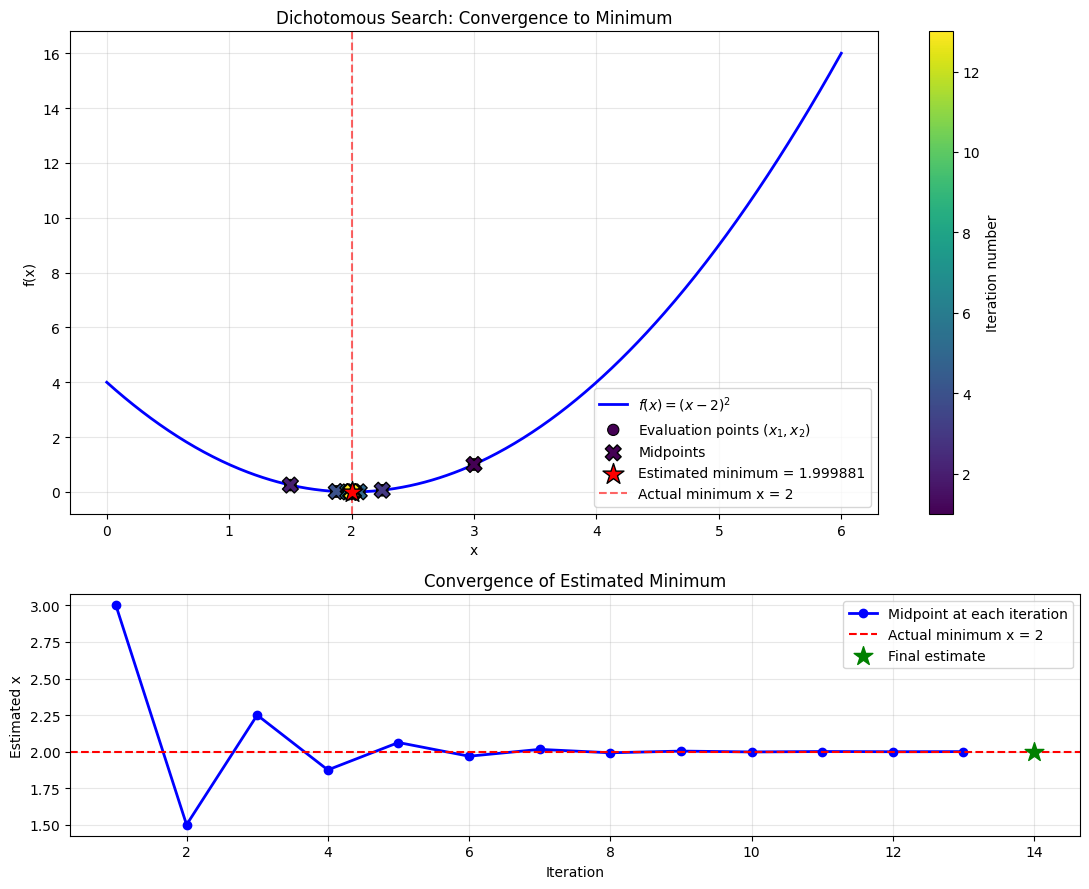

In [3]:
import matplotlib.pyplot as plt
import numpy as np
# ---------------------------------
# GRAPH 1: Function and search points
# ---------------------------------

x = np.linspace(0, 6, 500)
y = F_x(x)

probe_x = []
probe_y = []
probe_iteration = []

mid_x = []
mid_y = []
mid_iteration = []

for item in history:

    k = item["iteration"]

    # Two evaluated points
    probe_x.extend([item["x1"], item["x2"]])
    probe_y.extend([item["f1"], item["f2"]])
    probe_iteration.extend([k, k])

    # Midpoint in every iteration
    mid_x.append(item["mid"])
    mid_y.append(F_x(item["mid"]))
    mid_iteration.append(k)


fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 9),
    gridspec_kw={"height_ratios": [2, 1]}
)

# Plot original function
ax1.plot(x, y, color="blue", linewidth=2,
         label=r"$f(x)=(x-2)^2$")

# Plot x1 and x2 evaluation points
ax1.scatter(
    probe_x, probe_y,
    c=probe_iteration,
    cmap="viridis",
    s=65,
    edgecolors="black",
    linewidths=0.8,
    label=r"Evaluation points ($x_1,x_2$)",
    zorder=3
)

# Plot midpoint of each iteration
mid_sc = ax1.scatter(
    mid_x, mid_y,
    c=mid_iteration,
    cmap="viridis",
    marker="X",
    s=130,
    edgecolors="black",
    linewidths=1,
    label="Midpoints",
    zorder=4
)

# Final estimated minimum
ax1.scatter(
    x_min, F_x(x_min),
    color="red",
    marker="*",
    s=250,
    edgecolors="black",
    label=f"Estimated minimum = {x_min:.6f}",
    zorder=5
)

# Actual minimum
ax1.axvline(2, color="red", linestyle="--",
            alpha=0.6, label="Actual minimum x = 2")

ax1.set_title("Dichotomous Search: Convergence to Minimum")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x)")
ax1.grid(True, alpha=0.3)
ax1.legend()

fig.colorbar(mid_sc, ax=ax1, label="Iteration number")


# ---------------------------------
# GRAPH 2: Convergence of midpoint
# ---------------------------------

iterations = [item["iteration"] for item in history]

ax2.plot(
    iterations, mid_x,
    marker="o",
    linewidth=2,
    color="blue",
    label="Midpoint at each iteration"
)

ax2.axhline(
    y=2,
    color="red",
    linestyle="--",
    label="Actual minimum x = 2"
)

ax2.scatter(
    len(history) + 1, x_min,
    color="green",
    marker="*",
    s=200,
    label="Final estimate",
    zorder=5
)

ax2.set_title("Convergence of Estimated Minimum")
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Estimated x")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()